# Will Your Medical Supplier Accept Medicare's Price?
### An analysis of 56,960 Medicare medical-equipment suppliers (CRISP-DM)

**Author:** Sultan Bahamburah

This notebook follows the **CRISP-DM** process:

1. **Business Understanding** – what problem are we solving and which questions do we ask?
2. **Data Understanding** – *gather* and *assess* the data (exploratory data analysis).
3. **Data Preparation** – *clean* the data and engineer features.
4. **Modeling** – *analyze* the questions and *model* supplier behaviour.
5. **Evaluation** – measure how well the model works and what that means.
6. **Deployment / Communication** – *visualize* the results, run a new scenario, and summarise
   (see also `README.md` and the blog post in `blog/`).

## 1. Business Understanding

People on Medicare who need medical equipment (walkers, oxygen, CPAP machines, wheelchairs, diabetic
supplies) have to buy it from an enrolled **DMEPOS** supplier (Durable Medical Equipment, Prosthetics,
Orthotics and Supplies). One field in the supplier directory matters a lot to the patient's wallet:

* **Accepts assignment = True**: the supplier agrees to take the Medicare-approved amount as full payment.
  The patient pays only the usual 20% coinsurance (after the deductible), and the supplier bills Medicare directly.
* **Accepts assignment = False**: the supplier can charge more than the approved amount (and may ask the
  patient to pay up front and claim the money back from Medicare).

So whether a supplier accepts assignment directly affects how much a patient pays. This project asks:

| # | Business question | Answered with |
|---|---|---|
| Q1 | Which **types of supplier** are most and least likely to accept assignment? | Rate table, bar chart, chi-square test |
| Q2 | How much does acceptance **vary by state**? | Rate by state, chart, chi-square test |
| Q3 | Is accepting assignment a **local or a corporate decision**? | Chain-level consistency statistic, chart |
| Q4 | Which **products** are hardest to find from a supplier that accepts assignment? | Rate by product category, chart |
| Q5 | Can we **predict** whether a supplier accepts assignment, and what drives the prediction? | Random forest vs. baselines, grouped cross-validation |

### Setup

The libraries used are the ones listed for the project: `pandas`, `numpy`, `scikit-learn`, `matplotlib`
and `seaborn`. `scipy` (installed as a dependency of scikit-learn) is used for the chi-square tests.
All constants are defined once here so the notebook is easy to re-run or adapt.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             roc_auc_score)
from sklearn.model_selection import (GroupKFold, GroupShuffleSplit,
                                     cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path('data/Medical-Equipment-Suppliers.zip')  # zipped CSV
IMAGE_DIR = Path('images')
IMAGE_DIR.mkdir(exist_ok=True)

TARGET = 'acceptsassignement'          # column name as spelled in the data
MULTI_VALUE_SEP = '|'                  # separator in the list-type columns
MEDICARE_START = pd.Timestamp('1966-07-01')
RANDOM_STATE = 42

# Chart palette: two colour-blind-safe hues plus neutral ink colours
ACCEPT_COLOR = '#2a78d6'               # blue   = accepts assignment
DECLINE_COLOR = '#eb6834'              # orange = does not accept
INK_PRIMARY = '#0b0b0b'
INK_SECONDARY = '#52514e'
GRID_COLOR = '#e4e3df'

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GRID_COLOR,
    'grid.color': GRID_COLOR,
    'axes.labelcolor': INK_SECONDARY,
    'xtick.color': INK_SECONDARY,
    'ytick.color': INK_SECONDARY,
    'axes.titleweight': 'bold',
    'axes.titlesize': 13,
    'axes.titlecolor': INK_PRIMARY,
})
pd.set_option('display.max_colwidth', 60)

### Helper functions

These reusable functions keep the analysis DRY: the same rate calculation and the same chart code
are used for specialties, states and products.

In [2]:
def save_figure(fig, filename):
    """Save a matplotlib figure to the image folder at blog-ready resolution.

    Args:
        fig (matplotlib.figure.Figure): Figure to save.
        filename (str): File name (e.g. 'q1_specialty.png').
    """
    fig.savefig(IMAGE_DIR / filename, dpi=150, bbox_inches='tight')


def explode_multi_value(df, column, fill_value=None):
    """Turn a '|'-separated list column into one row per value.

    Args:
        df (pd.DataFrame): Data containing ``column``.
        column (str): Name of the multi-value column.
        fill_value (str, optional): Value used for missing lists. Rows with
            missing lists are dropped when None.

    Returns:
        pd.DataFrame: Copy of ``df`` with one row per list item in ``column``.
    """
    values = df[column]
    if fill_value is not None:
        values = values.fillna(fill_value)
    exploded = df.assign(**{column: values.str.split(MULTI_VALUE_SEP)})
    return exploded.explode(column).dropna(subset=[column])


def acceptance_rate_by(df, column, min_count=1, multi_value=False):
    """Compute the share of suppliers accepting assignment per category.

    Args:
        df (pd.DataFrame): Cleaned supplier data.
        column (str): Category column to group by.
        min_count (int): Minimum number of suppliers for a category to be kept.
        multi_value (bool): True if ``column`` holds '|'-separated lists.

    Returns:
        pd.DataFrame: Columns ``acceptance_rate`` and ``suppliers``, sorted by
        rate (ascending).
    """
    data = explode_multi_value(df, column) if multi_value else df
    rates = (data.groupby(column)[TARGET]
                 .agg(acceptance_rate='mean', suppliers='size'))
    rates = rates[rates['suppliers'] >= min_count]
    return rates.sort_values('acceptance_rate')


def plot_acceptance_bars(rates, title, filename, overall_rate,
                         label_width=45):
    """Draw a horizontal bar chart of acceptance rates with a reference line.

    Bars above the overall rate are blue, bars below are orange, so the
    reader can see at a glance which categories beat the national average.

    Args:
        rates (pd.DataFrame): Output of :func:`acceptance_rate_by`.
        title (str): Chart title.
        filename (str): Name of the PNG written to the image folder.
        overall_rate (float): National acceptance rate (reference line).
        label_width (int): Maximum characters shown per category label.

    Returns:
        matplotlib.axes.Axes: The chart axes.
    """
    labels = [name if len(name) <= label_width
              else name[:label_width - 1] + '…' for name in rates.index]
    colors = [ACCEPT_COLOR if rate >= overall_rate else DECLINE_COLOR
              for rate in rates['acceptance_rate']]
    height = max(3.5, 0.32 * len(rates) + 1.2)
    fig, ax = plt.subplots(figsize=(9, height))
    ax.barh(labels, rates['acceptance_rate'], color=colors, height=0.7)
    ax.axvline(overall_rate, color=INK_SECONDARY, linestyle='--',
               linewidth=1, zorder=1)
    ax.text(overall_rate, len(rates) - 0.3,
            f' all suppliers: {overall_rate:.0%}', color=INK_SECONDARY,
            fontsize=9, va='bottom')
    for y_pos, (rate, count) in enumerate(
            zip(rates['acceptance_rate'], rates['suppliers'])):
        ax.text(rate + 0.01, y_pos, f'{rate:.0%}  (n={count:,})',
                va='center', fontsize=8, color=INK_SECONDARY, zorder=3,
                bbox={'facecolor': '#fcfcfb', 'edgecolor': 'none',
                      'pad': 1})
    ax.set_xlim(0, 1.18)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_xlabel('Share of suppliers that accept Medicare assignment')
    ax.set_title(title, loc='left')
    ax.grid(axis='y', visible=False)
    fig.tight_layout()
    save_figure(fig, filename)
    return ax


def chi_square_test(df, column):
    """Run a chi-square test of independence between a column and the target.

    Args:
        df (pd.DataFrame): Cleaned supplier data.
        column (str): Single-valued categorical column.

    Returns:
        pd.Series: Chi-square statistic, degrees of freedom, p-value and
        Cramér's V (effect size between 0 and 1).
    """
    table = pd.crosstab(df[column], df[TARGET])
    chi2, p_value, dof, _ = chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return pd.Series({'chi2': chi2, 'dof': dof, 'p_value': p_value,
                      'cramers_v': cramers_v})

## 2. Data Understanding

### 2.1 Gather

The data is the **Medicare Supplier Directory** published by the Centers for Medicare & Medicaid Services
(CMS) on the [CMS Provider Data Catalog](https://data.cms.gov/provider-data/) (field definitions in the
[Supplier Directory Data Dictionary](https://data.cms.gov/provider-data/sites/default/files/data_dictionaries/supplier/Supplier_Directory_Data_Dictionary.pdf)): one row per enrolled
medical-equipment supplier location. The CSV is stored **zipped** (about 4 MB instead of 32 MB) so it fits
GitHub's upload limit; pandas reads the zip directly. ZIP codes and phone numbers are read as text so leading zeros are kept.

In [3]:
def load_data(path):
    """Load the CMS supplier directory CSV (plain or zipped).

    Args:
        path (Path or str): Location of the CSV or zipped CSV file.

    Returns:
        pd.DataFrame: Raw supplier data with ZIP and phone kept as text.
    """
    return pd.read_csv(path, dtype={'practicezip9code': str,
                                    'telephonenumber': str})


raw = load_data(DATA_PATH)
print(f'{raw.shape[0]:,} rows x {raw.shape[1]} columns')
raw.head(3)

56,960 rows x 17 columns


,provider_id,acceptsassignement,participationbegindate,businessname,practicename,practiceaddress1,practiceaddress2,practicecity,practicestate,practicezip9code,telephonenumber,specialitieslist,providertypelist,supplieslist,latitude,longitude,is_contracted_for_cba
0,34363383,True,2026-06-02,BRIDGEPOINT PHARMACY INC,BRIDGEPOINT PHARMACY INC,247 MILL ST,NaN,BRISTOL,PA,190074803,2678125355,Pharmacy,NaN,Epoetin|Immunosuppressive Drugs|Infusion Drugs|Nebulizer...,40.095745,-74.857987,False
1,34363341,True,2026-05-28,LENSHOP,LENSHOP,BO SUMIDERO CARR 173 KM 18.5,NaN,AGUAS BUENAS,PR,00703,7873716437,Optician,NaN,Prosthetic Lenses: Conventional Eyeglasses,18.219565,-66.129201,False
2,34363347,False,2026-05-27,PROSTHETICS LAB LTD LLC,PROSTHETICS LAB LTD LLC,1115 CLARKSON AVE,NaN,BROOKLYN,NY,112122728,7186769016,Orthotic Personnel|Prosthetic Personnel,CERTIFIED ORTH/PROS/PEDORTHIST,Orthoses: Custom Fabricated|Orthoses: Prefabricated (Non...,40.660512,-73.921475,False


### 2.2 Assess

#### Structure, types and duplicates

In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 56960 entries, 0 to 56959
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   provider_id             56960 non-null  int64  
 1   acceptsassignement      56960 non-null  bool   
 2   participationbegindate  56960 non-null  str    
 3   businessname            56960 non-null  str    
 4   practicename            56960 non-null  str    
 5   practiceaddress1        56960 non-null  str    
 6   practiceaddress2        12656 non-null  str    
 7   practicecity            56960 non-null  str    
 8   practicestate           56960 non-null  str    
 9   practicezip9code        56960 non-null  str    
 10  telephonenumber         56960 non-null  str    
 11  specialitieslist        56219 non-null  str    
 12  providertypelist        6681 non-null   str    
 13  supplieslist            56938 non-null  str    
 14  latitude                56960 non-null  float64
 

In [5]:
print('Duplicate rows:          ', raw.duplicated().sum())
print('Duplicate provider IDs:  ', raw['provider_id'].duplicated().sum())
print('Distinct values per column:')
raw.nunique().sort_values()

Duplicate rows:           0


Duplicate provider IDs:   0
Distinct values per column:


is_contracted_for_cba         1
acceptsassignement            2
practicestate                55
providertypelist            224
specialitieslist            270
practiceaddress2           3154
participationbegindate     6048
practicecity               6735
supplieslist               8368
businessname              17017
practicename              39540
latitude                  54722
longitude                 55048
practicezip9code          55182
practiceaddress1          55552
telephonenumber           56061
provider_id               56960
dtype: int64

#### Missing values

In [6]:
missing = (raw.isna().mean().mul(100).round(2)
              .rename('pct_missing').to_frame())
missing[missing['pct_missing'] > 0].sort_values('pct_missing',
                                                ascending=False)

,pct_missing
providertypelist,88.27
practiceaddress2,77.78
specialitieslist,1.30
supplieslist,0.04


#### The target variable

The target is roughly balanced (about 51% accept, 49% do not), so plain accuracy is a meaningful
metric. A model has to beat about 51% to be better than always guessing "accepts".

In [7]:
raw[TARGET].value_counts(normalize=True).rename('share').to_frame()

,share
acceptsassignement,
True,0.512676
False,0.487324


#### Multi-value columns

`specialitieslist`, `providertypelist` and `supplieslist` are **lists packed into one string**
(separated by `|`). One supplier can be, for example, both a *Pharmacy* and a *Grocery Store*, and can
sell dozens of product categories. These need special handling before they can be analysed or modelled.

In [8]:
for column in ['specialitieslist', 'providertypelist', 'supplieslist']:
    items = explode_multi_value(raw, column)[column]
    print(f'{column:18s}: {items.nunique():3d} distinct values, '
          f'most common = {items.value_counts().index[0]!r}')

specialitieslist  :  19 distinct values, most common = 'Pharmacy'
providertypelist  :  52 distinct values, most common = 'OXYGEN & EQUIPMENT'


supplieslist      :  91 distinct values, most common = 'Nebulizer Drugs'


#### Distributions and skewness (numeric features)

Two numeric features can be derived straight away: how many **years** a supplier has been enrolled
in Medicare, and how many **product categories** it supplies. Below we look at their distributions
and skewness.

In [9]:
enroll_date = pd.to_datetime(raw['participationbegindate'])
snapshot_date = enroll_date.max()
explore = pd.DataFrame({
    'years_enrolled': (snapshot_date - enroll_date).dt.days / 365.25,
    'n_supplies': raw['supplieslist'].str.count(r'\|') + 1,
    TARGET: raw[TARGET],
})
print(f'Data snapshot date (latest enrolment): {snapshot_date.date()}')
print('Earliest enrolment dates:',
      enroll_date.nsmallest(5).dt.date.tolist())
explore[['years_enrolled', 'n_supplies']].agg(['mean', 'median', 'skew'])

Data snapshot date (latest enrolment): 2026-10-13
Earliest enrolment dates: [datetime.date(1940, 1, 2), datetime.date(1940, 1, 2), datetime.date(1965, 7, 1), datetime.date(1965, 7, 1), datetime.date(1965, 7, 1)]


,years_enrolled,n_supplies
mean,12.790425,14.366434
median,9.848049,12.000000
skew,0.963026,1.443194


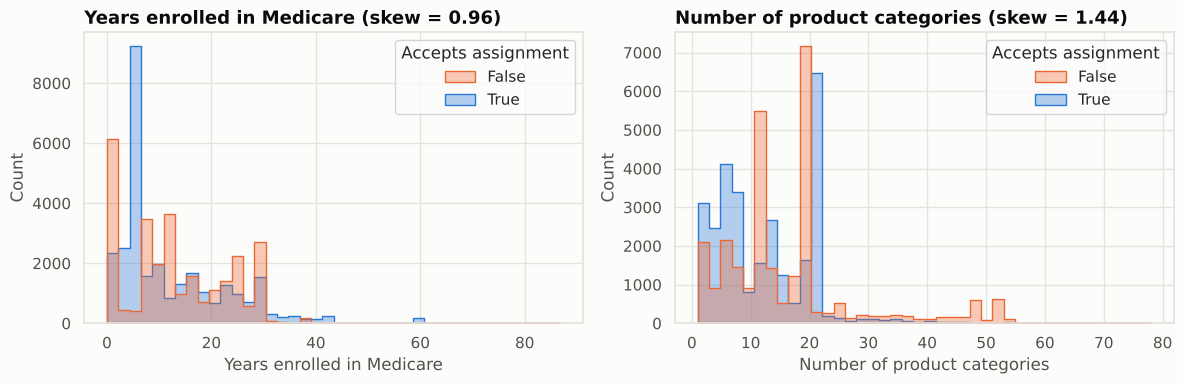

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, label in zip(
        axes, ['years_enrolled', 'n_supplies'],
        ['Years enrolled in Medicare', 'Number of product categories']):
    sns.histplot(data=explore, x=column, hue=TARGET, bins=40, ax=ax,
                 palette={True: ACCEPT_COLOR, False: DECLINE_COLOR},
                 element='step', alpha=0.35)
    ax.set_xlabel(label)
    ax.get_legend().set_title('Accepts assignment')
    ax.set_title(f'{label} (skew = {explore[column].skew():.2f})',
                 loc='left')
fig.tight_layout()
save_figure(fig, 'eda_distributions.png')

#### Geography

The latitude/longitude columns let us draw every supplier on a map. Coordinates outside the
mainland US are Alaska, Hawaii, Puerto Rico, Guam and other territories, so they are real and are
**not** outliers to be removed.

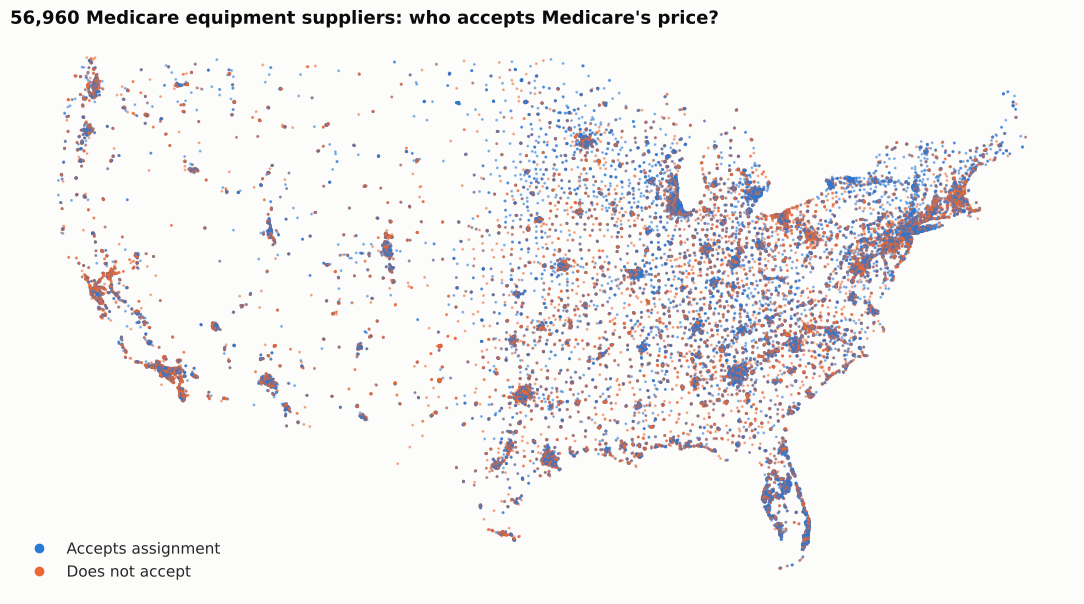

In [11]:
fig, ax = plt.subplots(figsize=(11, 6.2))
mainland = raw[raw['longitude'].between(-125, -66)
               & raw['latitude'].between(24, 50)]
# Shuffle so neither colour is always drawn on top of the other
mainland = mainland.sample(frac=1, random_state=RANDOM_STATE)
ax.scatter(mainland['longitude'], mainland['latitude'], s=1.2, alpha=0.45,
           c=np.where(mainland[TARGET], ACCEPT_COLOR, DECLINE_COLOR),
           rasterized=True)
ax.set_axis_off()
ax.set_title('56,960 Medicare equipment suppliers: '
             'who accepts Medicare\'s price?', loc='left')
ax.legend(handles=[plt.Line2D([], [], marker='o', linestyle='',
                              color=color, label=label)
                   for color, label in [(ACCEPT_COLOR, 'Accepts assignment'),
                                        (DECLINE_COLOR, 'Does not accept')]],
          frameon=False, loc='lower left')
fig.tight_layout()
save_figure(fig, 'header_map.png')

### 2.3 Summary of the exploration: does the data need cleaning?

**Yes.** The assessment found:

| Issue | Finding | Decision |
|---|---|---|
| Constant column | `is_contracted_for_cba` is `False` for every row | Drop: it carries no information |
| Contact / address details | `provider_id`, phone, street address, ZIP, practice name | Drop for modelling: identifiers, not drivers of behaviour |
| `practiceaddress2` | 78% missing (only suite numbers) | Drop: no analytic value |
| `providertypelist` | 88% missing | Missing here means *no extra provider type registered*, not "unknown", so fill with an empty list (all indicator columns = 0) |
| `specialitieslist` | 1.3% missing | Fill with an explicit **`Unknown`** category. These suppliers accept at a noticeably different rate (66%), so the missingness is informative and dropping them would bias the data |
| `supplieslist` | 22 rows missing | Fill with an empty list (`n_supplies = 0`). Too few rows to matter, but kept for completeness |
| Dates | 5 enrolments before Medicare existed (1940, 1965) | Data-entry errors: clip to Medicare's start date (1 July 1966) |
| Skewness | `years_enrolled` (skew ≈ 1.0) and `n_supplies` are right-skewed with **multiple peaks** | Tree models handle skew without transformation; the logistic-regression baseline uses standardised features |
| List columns | Three `|`-separated list columns | One-hot ("multi-hot") encode each list value into its own 0/1 column |
| Chains | The same `businessname` appears up to 7,739 times | Engineer a `chain_size` feature, and **group by business** when splitting train/test (explained in Q5) |

The odd, spiky shape of both histograms (for example, suppliers enrolled 3–5 years ago accept at over 90%)
is a first hint that a few very large chains dominate the data. Q3 investigates this.

## 3. Data Preparation (Clean)

In [12]:
DROP_COLUMNS = ['provider_id', 'practicename', 'practiceaddress1',
                'practiceaddress2', 'practicezip9code', 'telephonenumber',
                'is_contracted_for_cba']


def clean_data(df):
    """Clean the raw supplier directory and add engineered columns.

    Steps (see the assessment summary for the reasoning):
    drop identifier/constant columns, fix impossible enrolment dates, fill
    missing list columns, and add ``years_enrolled``, ``n_supplies``,
    ``n_specialties`` and ``chain_size``.

    Args:
        df (pd.DataFrame): Raw data from :func:`load_data`.

    Returns:
        pd.DataFrame: Cleaned data, one row per supplier location.
    """
    clean = df.drop(columns=DROP_COLUMNS).copy()

    enrolled = pd.to_datetime(clean['participationbegindate'])
    clean['participationbegindate'] = enrolled.clip(lower=MEDICARE_START)
    clean['years_enrolled'] = (
        (enrolled.max() - clean['participationbegindate']).dt.days / 365.25)

    clean['specialitieslist'] = clean['specialitieslist'].fillna('Unknown')
    clean['providertypelist'] = clean['providertypelist'].fillna('')
    clean['supplieslist'] = clean['supplieslist'].fillna('')

    clean['n_supplies'] = clean['supplieslist'].map(
        lambda text: len(text.split(MULTI_VALUE_SEP)) if text else 0)
    clean['n_specialties'] = (
        clean['specialitieslist'].str.count(r'\|') + 1)
    clean['chain_size'] = clean.groupby('businessname')[
        'businessname'].transform('size')
    return clean


suppliers = clean_data(raw)
OVERALL_RATE = suppliers[TARGET].mean()
print(f'Cleaned data: {suppliers.shape[0]:,} rows x '
      f'{suppliers.shape[1]} columns')
print('Remaining missing values:', suppliers.isna().sum().sum())
print(f'Overall acceptance rate: {OVERALL_RATE:.1%}')
suppliers.head(3)

Cleaned data: 56,960 rows x 14 columns
Remaining missing values: 0
Overall acceptance rate: 51.3%


,acceptsassignement,participationbegindate,businessname,practicecity,practicestate,specialitieslist,providertypelist,supplieslist,latitude,longitude,years_enrolled,n_supplies,n_specialties,chain_size
0,True,2026-06-02,BRIDGEPOINT PHARMACY INC,BRISTOL,PA,Pharmacy,,Epoetin|Immunosuppressive Drugs|Infusion Drugs|Nebulizer...,40.095745,-74.857987,0.364134,6,1,1
1,True,2026-05-28,LENSHOP,AGUAS BUENAS,PR,Optician,,Prosthetic Lenses: Conventional Eyeglasses,18.219565,-66.129201,0.377823,1,1,1
2,False,2026-05-27,PROSTHETICS LAB LTD LLC,BROOKLYN,NY,Orthotic Personnel|Prosthetic Personnel,CERTIFIED ORTH/PROS/PEDORTHIST,Orthoses: Custom Fabricated|Orthoses: Prefabricated (Non...,40.660512,-73.921475,0.380561,4,2,1


## 4. Analyze: answering the business questions

### Q1. Which types of supplier are most and least likely to accept assignment?

A supplier can list several specialties, so each supplier is counted once **for every** specialty it lists.
Specialties with fewer than 30 suppliers are left out because their rates would be unreliable.

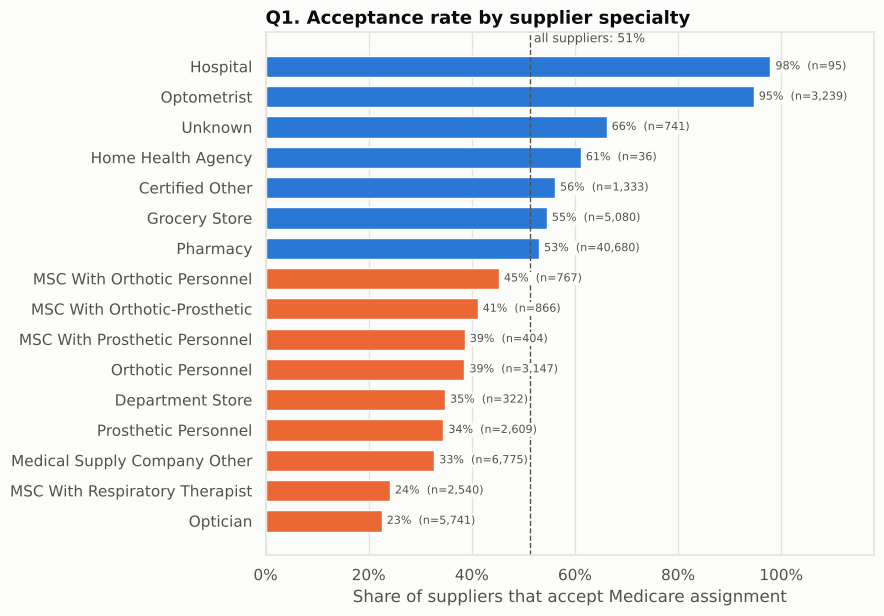

,acceptance_rate,suppliers
specialitieslist,,
Hospital,97.9%,95
Optometrist,94.7%,"3,239"
Unknown,66.1%,741
Home Health Agency,61.1%,36
Certified Other,56.1%,"1,333"
Grocery Store,54.5%,"5,080"
Pharmacy,53.0%,"40,680"
MSC With Orthotic Personnel,45.2%,767
MSC With Orthotic-Prosthetic,41.1%,866


In [13]:
specialty_rates = acceptance_rate_by(suppliers, 'specialitieslist',
                                     min_count=30, multi_value=True)
plot_acceptance_bars(specialty_rates,
                     'Q1. Acceptance rate by supplier specialty',
                     'q1_specialty.png', OVERALL_RATE)
plt.show()
specialty_rates.sort_values('acceptance_rate', ascending=False).style.format(
    {'acceptance_rate': '{:.1%}', 'suppliers': '{:,}'})

To check this isn't just noise, we run a chi-square test on each supplier's **primary** (first-listed)
specialty. Cramér's V measures the strength of the association (0 = none, 1 = perfect).

In [14]:
suppliers['primary_specialty'] = (
    suppliers['specialitieslist'].str.split(MULTI_VALUE_SEP).str[0])
chi_square_test(suppliers, 'primary_specialty').round(4)

chi2         4331.0077
dof            18.0000
p_value         0.0000
cramers_v       0.2757
dtype: float64

**Answer to Q1.** Supplier type matters a lot (p < 0.001, Cramér's V ≈ 0.28, a moderate effect).
**Optometrists (95%)** and **hospitals (98%)** almost always accept assignment. **Opticians (23%)** and
**medical supply companies with a respiratory therapist (24%)**, the businesses that typically supply
oxygen and breathing equipment, rarely do. Pharmacies, which make up 71% of the directory, sit close to
the national average (53%).

### Q2. How much does acceptance vary by state?

Only states and territories with at least 50 suppliers are shown.

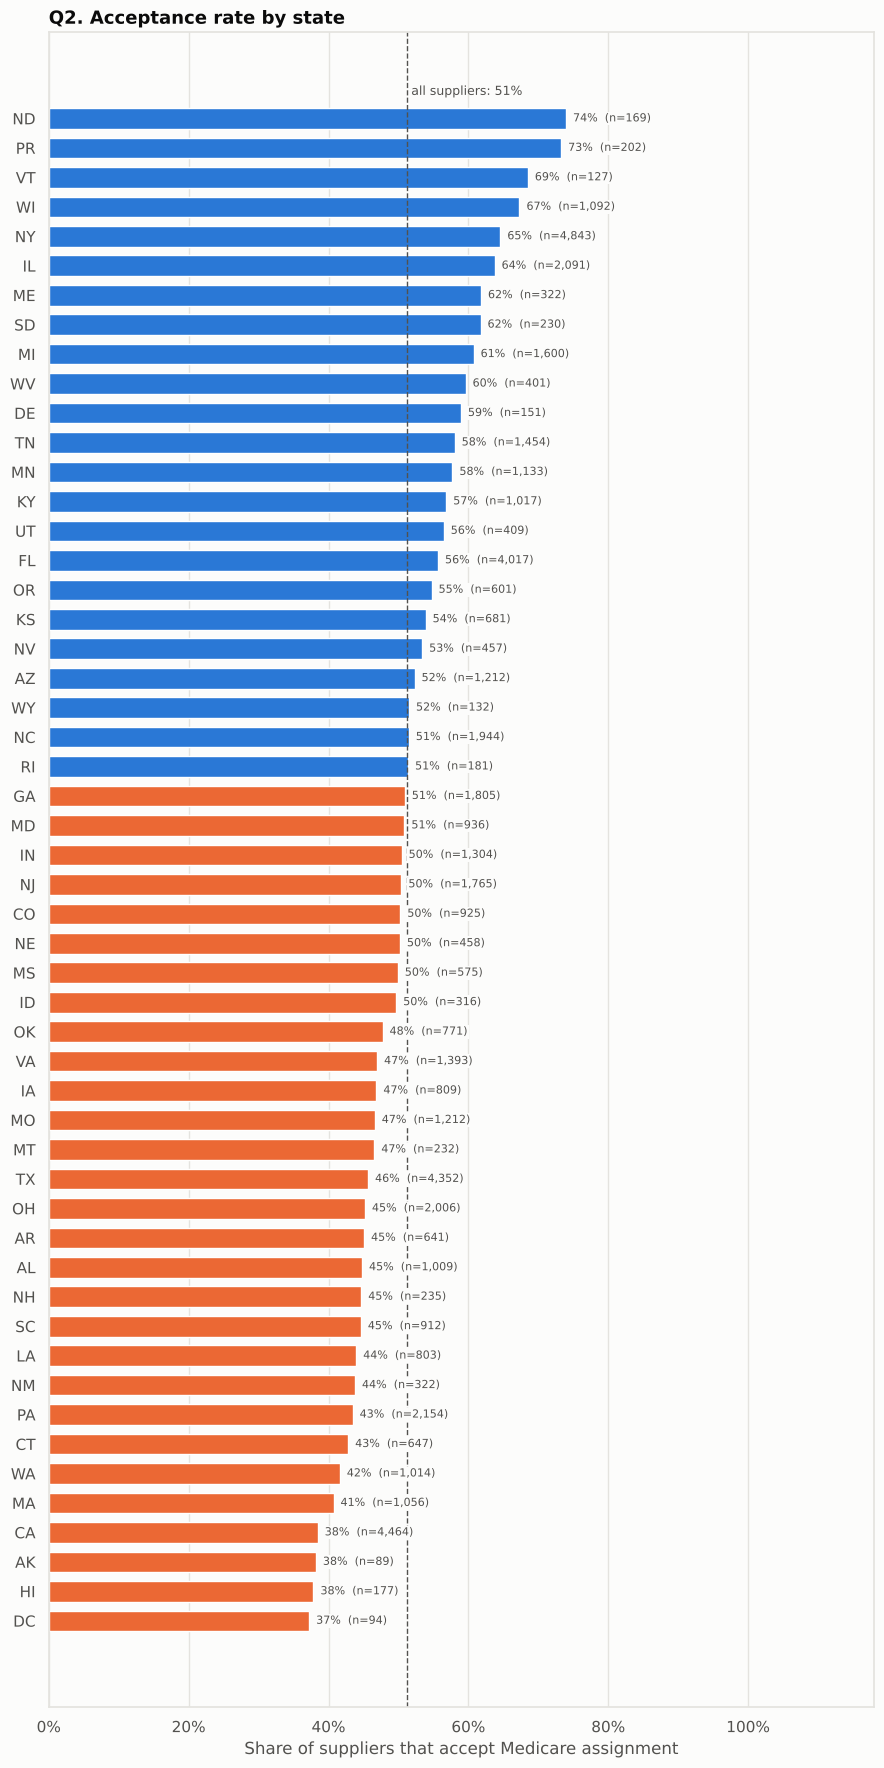

chi2         1540.9371
dof            54.0000
p_value         0.0000
cramers_v       0.1645
dtype: float64

Range: 37% (DC) to 74% (ND)


In [15]:
state_rates = acceptance_rate_by(suppliers, 'practicestate', min_count=50)
plot_acceptance_bars(state_rates, 'Q2. Acceptance rate by state',
                     'q2_state.png', OVERALL_RATE)
plt.show()
print(chi_square_test(suppliers, 'practicestate').round(4))
print(f"\nRange: {state_rates['acceptance_rate'].min():.0%} "
      f"({state_rates.index[0]}) to "
      f"{state_rates['acceptance_rate'].max():.0%} "
      f"({state_rates.index[-1]})")

**Answer to Q2.** Where a patient lives makes a real difference. Acceptance ranges from about **37% in
Washington DC and 38% in California** to **74% in North Dakota** and **73% in Puerto Rico**. Large states like New York (65%)
and Illinois (64%) are well above average, while California, Massachusetts and Washington are well below.
The association is statistically significant but weaker than supplier type (Cramér's V ≈ 0.16). Part of
the state effect simply reflects which chains dominate each state (see Q3).

### Q3. Is accepting assignment a local or a corporate decision?

If each store decided for itself, we would expect locations of the same company to disagree sometimes.
We test this by looking at every business name that appears at **two or more** locations.

In [16]:
def chain_policy_summary(df, min_locations=2):
    """Summarise how consistent assignment policy is within each business.

    Args:
        df (pd.DataFrame): Cleaned supplier data.
        min_locations (int): Minimum locations for a business to count as
            a chain.

    Returns:
        pd.DataFrame: One row per chain with ``locations``,
        ``acceptance_rate`` and ``uniform_policy`` (True when every
        location makes the same choice).
    """
    chains = (df.groupby('businessname')[TARGET]
                .agg(acceptance_rate='mean', locations='size'))
    chains = chains[chains['locations'] >= min_locations].copy()
    chains['uniform_policy'] = chains['acceptance_rate'].isin([0, 1])
    return chains.sort_values('locations', ascending=False)


chains = chain_policy_summary(suppliers)
share_in_chains = chains['locations'].sum() / len(suppliers)
print(f'Multi-location businesses:          {len(chains):,}')
print(f'Supplier locations in those chains: {share_in_chains:.0%}')
print(f"Chains with ONE policy everywhere:  "
      f"{chains['uniform_policy'].mean():.1%}")
big = chains[chains['locations'] >= 10]
print(f"...among chains with 10+ locations: "
      f"{big['uniform_policy'].mean():.1%} of {len(big)}")

Multi-location businesses:          2,312
Supplier locations in those chains: 74%
Chains with ONE policy everywhere:  98.2%
...among chains with 10+ locations: 99.3% of 291


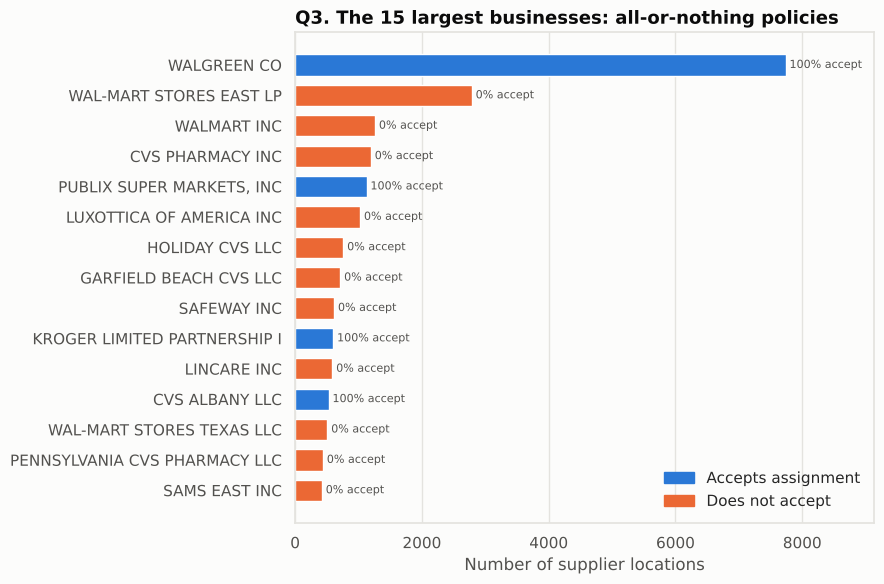

,acceptance_rate,locations,uniform_policy
businessname,,,
WALGREEN CO,1.0,7739,True
WAL-MART STORES EAST LP,0.0,2788,True
WALMART INC,0.0,1262,True
CVS PHARMACY INC,0.0,1196,True
"PUBLIX SUPER MARKETS, INC",1.0,1128,True
LUXOTTICA OF AMERICA INC,0.0,1026,True
HOLIDAY CVS LLC,0.0,761,True
GARFIELD BEACH CVS LLC,0.0,713,True
SAFEWAY INC,0.0,616,True


In [17]:
top_chains = chains.head(15).sort_values('locations')
fig, ax = plt.subplots(figsize=(9, 6))
colors = [ACCEPT_COLOR if rate >= 0.5 else DECLINE_COLOR
          for rate in top_chains['acceptance_rate']]
ax.barh(top_chains.index, top_chains['locations'],
        color=colors, height=0.7)
for y_pos, (count, rate) in enumerate(
        zip(top_chains['locations'], top_chains['acceptance_rate'])):
    ax.text(count + 60, y_pos, f'{rate:.0%} accept', va='center',
            fontsize=8, color=INK_SECONDARY)
ax.set_xlabel('Number of supplier locations')
ax.set_title('Q3. The 15 largest businesses: all-or-nothing policies',
             loc='left')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ACCEPT_COLOR),
                   plt.Rectangle((0, 0), 1, 1, color=DECLINE_COLOR)],
          labels=['Accepts assignment', 'Does not accept'],
          frameon=False, loc='lower right')
ax.set_xlim(0, top_chains['locations'].max() * 1.18)
ax.grid(axis='y', visible=False)
fig.tight_layout()
save_figure(fig, 'q3_chains.png')
plt.show()
top_chains.sort_values('locations', ascending=False)

The chain effect also explains the strange spike in the enrolment histogram: almost every location
of the biggest chain re-enrolled in the same window, so "years enrolled" partly acts as a stand-in for
"which company".

In [18]:
walgreens = suppliers['businessname'].eq('WALGREEN CO')
tenure_band = pd.cut(suppliers['years_enrolled'], [0, 3, 5, 10, 100],
                     labels=['<3 yrs', '3-5 yrs', '5-10 yrs', '10+ yrs'])
(suppliers.assign(tenure_band=tenure_band, is_walgreens=walgreens)
          .groupby('tenure_band', observed=True)
          .agg(suppliers=(TARGET, 'size'),
               acceptance_rate=(TARGET, 'mean'),
               walgreens_share=('is_walgreens', 'mean'))
          .style.format({'acceptance_rate': '{:.0%}',
                         'walgreens_share': '{:.0%}',
                         'suppliers': '{:,}'}))

,suppliers,acceptance_rate,walgreens_share
tenure_band,,,
<3 yrs,"9,553",34%,0%
3-5 yrs,"10,212",96%,76%
5-10 yrs,"9,585",44%,0%
10+ yrs,"27,609",43%,0%


**Answer to Q3.** It's a **corporate decision**. 74% of supplier locations belong to a multi-location business,
and **98% of those businesses apply one policy at every location** (99% for chains with 10+ sites).
Brands that look alike behave in opposite ways: every Walgreens and Publix location accepts assignment, while
Walmart, most CVS entities, Luxottica and Lincare locations do not. For a patient, the brand on the door tells
you more than the address.

### Q4. Which products are hardest to find from a supplier that accepts assignment?

For each product category supplied by at least 500 suppliers, we compute the share of those suppliers
that accept assignment. The 15 lowest are shown.

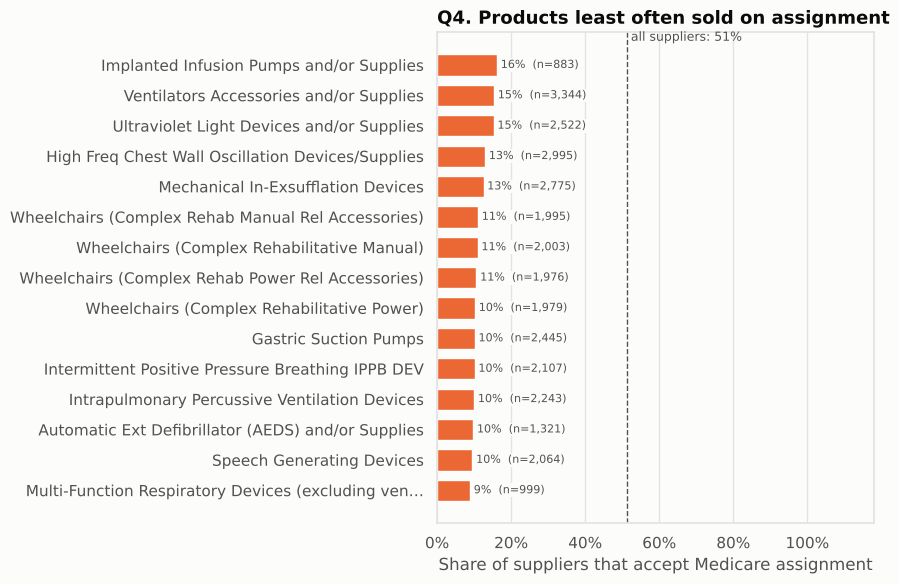

Most-often-assigned products:


,acceptance_rate,suppliers
supplieslist,,
Diabetic Shoes and Inserts,64.7%,"13,450"
Diabetic Shoes/Inserts - Custom,78.1%,"10,306"
Prosthetic Lenses: Conventional Contact Lenses,90.0%,"3,371"
Prosthetic Lenses: Prosthetics Cataract Lenses,91.8%,"1,601"
"Enteral Nutrients, Equipment and/or Supplies",94.9%,"6,296"


In [19]:
product_rates = acceptance_rate_by(suppliers, 'supplieslist', min_count=500,
                                   multi_value=True)
plot_acceptance_bars(product_rates.head(15),
                     'Q4. Products least often sold on assignment',
                     'q4_products.png', OVERALL_RATE, label_width=50)
plt.show()
print('Most-often-assigned products:')
product_rates.tail(5).style.format({'acceptance_rate': '{:.1%}',
                                    'suppliers': '{:,}'})

**Answer to Q4.** Patients needing complex, high-cost equipment have the fewest options. Only about **1 in 10**
suppliers of **complex rehab power wheelchairs, speech-generating devices, defibrillators and respiratory
devices** accept assignment, which is where paying above the approved amount hurts most. By contrast, contact
and cataract lenses (90%+) and enteral nutrition (95%) are usually sold on assignment.

## 5. Model: Q5. Can we predict whether a supplier accepts assignment?

### 5.1 Feature engineering and categorical handling

* **List columns** (specialties, products, provider types) are **multi-hot encoded**: one 0/1 column per value.
  A normal one-hot encoder can't be used because a supplier can have several values at once.
  Provider types seen fewer than 100 times are dropped to avoid very sparse columns.
* **State** is a single-valued nominal variable, so it is **one-hot encoded**. There is no natural order
  among states, which rules out label encoding.
* **Numeric features**: `years_enrolled`, `n_supplies`, `n_specialties`, and `log(chain_size)`
  (log-transformed because chain size runs from 1 to 7,739).
* **Excluded**: `businessname` (it would let the model memorise chains rather than learn patterns) and
  latitude/longitude (state already captures geography, and coordinates lowered grouped cross-validation scores
  during experimentation).

In [20]:
def multi_hot(series, prefix, min_count=1):
    """Multi-hot encode a '|'-separated list column.

    Args:
        series (pd.Series): Column of '|'-separated strings ('' = empty).
        prefix (str): Prefix for the new column names.
        min_count (int): Minimum number of rows a value must appear in.

    Returns:
        pd.DataFrame: One 0/1 integer column per retained value.
    """
    dummies = series.str.get_dummies(sep=MULTI_VALUE_SEP)
    dummies = dummies.loc[:, dummies.sum() >= min_count]
    return dummies.add_prefix(f'{prefix}_')


def build_features(df):
    """Create the model feature matrix and target vector.

    Args:
        df (pd.DataFrame): Cleaned supplier data from :func:`clean_data`.

    Returns:
        tuple: ``(X, y)`` where X is a numeric DataFrame and y a 0/1 Series.
    """
    numeric = pd.DataFrame({
        'years_enrolled': df['years_enrolled'],
        'n_supplies': df['n_supplies'],
        'n_specialties': df['n_specialties'],
        'log_chain_size': np.log(df['chain_size']),
    })
    features = pd.concat([
        numeric,
        multi_hot(df['specialitieslist'], 'specialty'),
        multi_hot(df['supplieslist'], 'supply'),
        multi_hot(df['providertypelist'], 'provtype', min_count=100),
        pd.get_dummies(df['practicestate'], prefix='state', dtype=int),
    ], axis=1)
    return features, df[TARGET].astype(int)


X, y = build_features(suppliers)
groups = suppliers['businessname']
print(f'Feature matrix: {X.shape[0]:,} rows x {X.shape[1]} features')

Feature matrix: 56,960 rows x 183 features


### 5.2 Choosing the evaluation strategy: why the split must be grouped by business

Q3 showed that locations of the same business behave identically. With a normal random split, Walgreens stores
would land in both the training and test sets, and the model could score highly just by recognising
Walgreens. That would overstate how well it works on a **supplier it has never seen**.

We therefore use **`GroupKFold`** (5 folds) with `businessname` as the group, so every location of a business
ends up on the same side of the split. The cell below shows how much a random split would flatter the model.

In [21]:
forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                n_jobs=-1, random_state=RANDOM_STATE)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
random_split_accuracy = forest.fit(X_tr, y_tr).score(X_te, y_te)
print(f'Random-split accuracy (optimistic, leaks chains): '
      f'{random_split_accuracy:.1%}')

Random-split accuracy (optimistic, leaks chains): 90.1%


### 5.3 Train and compare models with grouped cross-validation

Three models are compared:

1. **Random-guess baseline**: guesses "accepts" or "does not accept" at random in proportion to the class
   shares seen in training. Any useful model must beat this. (A majority-class baseline is misleading here,
   because whole chains move between folds, so the majority class in training is often the minority in validation.)
2. **Logistic regression** (with standardised features): a simple, interpretable linear model.
3. **Random forest**: an ensemble of decision trees. It handles skewed features and interactions
   (e.g. *pharmacy* + *specific state*) without manual tuning.

In [22]:
MODELS = {
    'Random-guess baseline': DummyClassifier(strategy='stratified',
                                             random_state=RANDOM_STATE),
    'Logistic regression': make_pipeline(
        StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)),
    'Random forest': forest,
}
SCORING = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']


def evaluate_models(models, X, y, groups, n_splits=5):
    """Score several models with grouped k-fold cross-validation.

    Args:
        models (dict): Mapping of model name to unfitted estimator.
        X (pd.DataFrame): Feature matrix.
        y (pd.Series): Binary target.
        groups (pd.Series): Group labels; rows sharing a label never appear
            in both the training and the validation fold.
        n_splits (int): Number of folds.

    Returns:
        pd.DataFrame: Mean and standard deviation of each metric per model.
    """
    rows = {}
    for name, model in models.items():
        scores = cross_validate(model, X, y, groups=groups,
                                cv=GroupKFold(n_splits=n_splits),
                                scoring=SCORING)
        rows[name] = {f'{metric} ({stat})': func(scores[f'test_{metric}'])
                      for metric in SCORING
                      for stat, func in [('mean', np.mean), ('std', np.std)]}
    return pd.DataFrame(rows).T


cv_results = evaluate_models(MODELS, X, y, groups)
cv_results.style.format('{:.3f}')

,accuracy (mean),accuracy (std),precision (mean),precision (std),recall (mean),recall (std),f1 (mean),f1 (std),roc_auc (mean),roc_auc (std)
Random-guess baseline,0.478,0.021,0.509,0.181,0.513,0.049,0.489,0.039,0.495,0.003
Logistic regression,0.801,0.036,0.785,0.075,0.776,0.103,0.778,0.080,0.831,0.048
Random forest,0.826,0.046,0.797,0.079,0.835,0.092,0.813,0.071,0.876,0.053


### 5.4 Evaluate the chosen model on a held-out set of unseen businesses

The random forest gives the best accuracy, F1 and ROC AUC, so we inspect it more closely on a single grouped
80/20 split (every business in the test set is unseen during training).

In [23]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2,
                             random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

forest.fit(X_train, y_train)
test_proba = forest.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= 0.5).astype(int)

print(f'Test set: {len(test_idx):,} locations from '
      f'{groups.iloc[test_idx].nunique():,} unseen businesses')
print(f'ROC AUC: {roc_auc_score(y_test, test_proba):.3f}\n')
print(classification_report(y_test, test_pred,
                            target_names=['Does not accept', 'Accepts']))

Test set: 10,869 locations from 3,404 unseen businesses
ROC AUC: 0.916

                 precision    recall  f1-score   support

Does not accept       0.89      0.82      0.86      6297
        Accepts       0.78      0.87      0.82      4572

       accuracy                           0.84     10869
      macro avg       0.84      0.84      0.84     10869
   weighted avg       0.84      0.84      0.84     10869



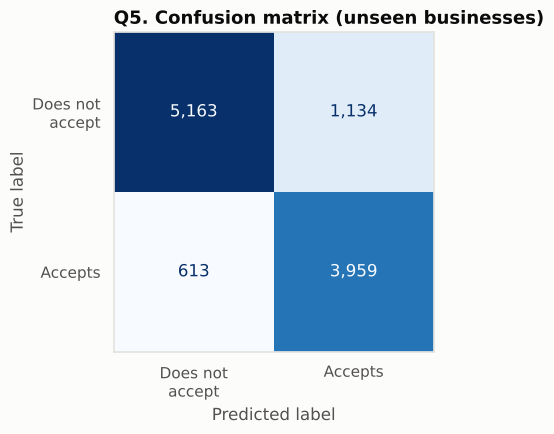

In [24]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=['Does not\naccept', 'Accepts'],
    cmap='Blues', colorbar=False, values_format=',', ax=ax)
ax.set_title('Q5. Confusion matrix (unseen businesses)', loc='left')
ax.grid(False)
fig.tight_layout()
save_figure(fig, 'q5_confusion_matrix.png')

**What the metrics tell us**

* **Accuracy** is the share of all suppliers classified correctly. Grouped cross-validation gives about
  **83%** (84% on the hold-out set above), against roughly **50%** for random guessing. The random split's
  ~90% shows how much memorising chains would have inflated the score.
* **Precision** (for "accepts"): when the model says a supplier accepts assignment, how often it really does.
  On the hold-out set this is **78%**, so about 1 in 5 "yes" predictions is wrong. This matters for a
  patient, because a false "yes" can mean an unexpected bill.
* **Recall** (for "accepts"): of the suppliers that really accept assignment, the share the model finds
  (**87%** on the hold-out set). The model leans slightly towards saying "accepts".
* **F1** is the balance (harmonic mean) of precision and recall (≈ 0.81 in cross-validation).
* **ROC AUC ≈ 0.88** (cross-validation): if we pick one accepting and one non-accepting supplier at random,
  the model ranks the accepting one higher about 88% of the time, independent of the 0.5 threshold.
* The **standard deviation across folds is large** (several points). This is expected: one fold can contain an
  entire 7,700-location chain, and a single wrong guess about a chain's policy moves the score a lot.
  The model learns *patterns* (supplier type, products, state, size), but it can't know a brand-new
  chain's corporate policy for certain.

### 5.5 What drives the predictions?

The random forest's feature importances show which inputs the trees rely on most.

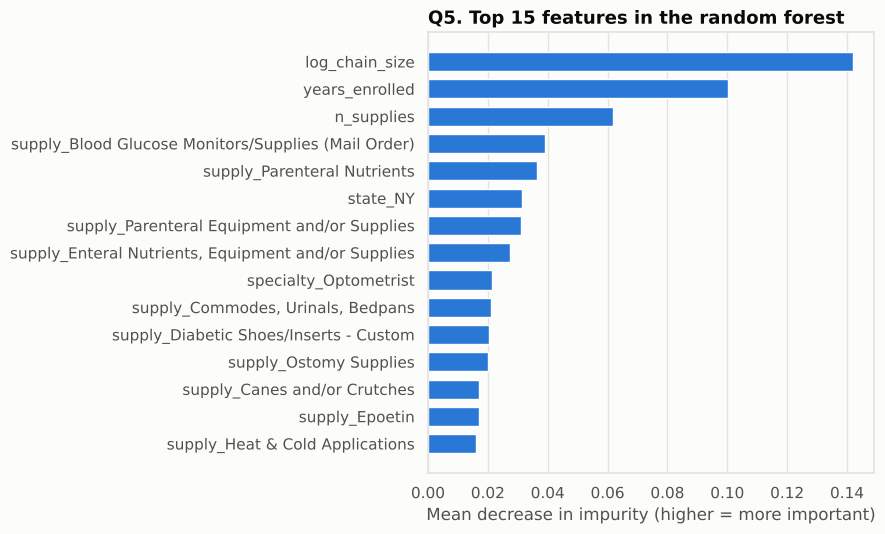

In [25]:
importances = (pd.Series(forest.feature_importances_, index=X.columns)
                 .sort_values(ascending=False).head(15).sort_values())
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importances.index, importances.values, color=ACCEPT_COLOR,
        height=0.7)
ax.set_xlabel('Mean decrease in impurity (higher = more important)')
ax.set_title('Q5. Top 15 features in the random forest', loc='left')
ax.grid(axis='y', visible=False)
fig.tight_layout()
save_figure(fig, 'q5_feature_importance.png')

**Answer to Q5.** Yes, reasonably well. For businesses the model has never seen, it is right about **83% of the
time** (ROC AUC ≈ 0.88), against about 50% for random guessing. The strongest signals are **chain size, how long
the supplier has been enrolled, and how many product categories it sells**, followed by specific product lines
(mail-order diabetic supplies, parenteral and enteral nutrition), being in **New York**, and being an
**optometrist**. This matches the descriptive findings in Q1–Q4. Note that `years_enrolled` partly stands in
for chain membership (see the tenure table in Q3). (Impurity-based importance favours continuous features with many
possible split points, so the exact ranking of the numeric features should be read with some caution.)

## 6. Deployment: predicting a new scenario

**Scenario.** *Fatima, 72, lives in Toledo, Ohio, and has just had cataract surgery with a lens implant.
Medicare Part B covers **one pair of eyeglasses (standard frames) or one set of contact lenses** after this
surgery, bought from a Medicare-enrolled supplier. She pays 20% of the Medicare-approved amount, but only if
the supplier accepts assignment; otherwise the supplier can charge more. She has three options nearby:*

* **Supplier A**: an independent optometrist's practice (eyeglasses and contact lenses).
* **Supplier B**: an independent optician's shop (eyeglasses, contact lenses and cataract lenses).
* **Supplier C**: a store belonging to a national optical chain with about 1,000 locations, selling
  the same products as B. The model has never seen this chain.

Each supplier has been enrolled for 10 years, close to the median. (The tenure table in Q3 showed that
3–5 years is dominated by one chain, so we avoid that window to keep the comparison about supplier type.)
We train the random forest on **all** the data and score the three hypothetical suppliers.

In [26]:
def make_supplier(specialties, supplies, state, years_enrolled,
                  chain_size=1, provider_types=()):
    """Build a one-row feature frame for a hypothetical supplier.

    Args:
        specialties (list of str): Supplier specialties.
        supplies (list of str): Product categories supplied.
        state (str): Two-letter state code.
        years_enrolled (float): Years since Medicare enrolment.
        chain_size (int): Number of locations under the same business.
        provider_types (iterable of str): Extra provider types, if any.

    Returns:
        pd.DataFrame: A single row aligned to the training columns ``X``.
    """
    row = pd.DataFrame(0, index=[0], columns=X.columns, dtype=float)
    row.loc[0, ['years_enrolled', 'n_supplies', 'n_specialties',
                'log_chain_size']] = [years_enrolled, len(supplies),
                                      len(specialties), np.log(chain_size)]
    flags = ([f'specialty_{s}' for s in specialties]
             + [f'supply_{s}' for s in supplies]
             + [f'provtype_{p}' for p in provider_types]
             + [f'state_{state}'])
    unknown = [flag for flag in flags if flag not in X.columns]
    if unknown:
        raise ValueError(f'Unknown feature values: {unknown}')
    row.loc[0, flags] = 1
    return row


GLASSES = 'Prosthetic Lenses: Conventional Eyeglasses'
CONTACTS = 'Prosthetic Lenses: Conventional Contact Lenses'
CATARACT = 'Prosthetic Lenses: Prosthetics Cataract Lenses'

scenario_suppliers = {
    'A: independent optometrist': dict(
        specialties=['Optometrist'], supplies=[GLASSES, CONTACTS]),
    'B: independent optician': dict(
        specialties=['Optician'], supplies=[GLASSES, CONTACTS, CATARACT]),
    'C: national optical chain store': dict(
        specialties=['Optician'], supplies=[GLASSES, CONTACTS, CATARACT],
        chain_size=1000),
}
scenario = pd.concat(
    [make_supplier(state='OH', years_enrolled=10, **profile)
     for profile in scenario_suppliers.values()], ignore_index=True)

final_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                     n_jobs=-1, random_state=RANDOM_STATE)
final_model.fit(X, y)
scenario_proba = final_model.predict_proba(scenario)[:, 1]
scenario_result = pd.DataFrame({
    'supplier': list(scenario_suppliers),
    'probability_accepts_assignment': scenario_proba.round(2),
    'prediction': np.where(scenario_proba >= 0.5, 'Accepts',
                           'Does not accept'),
})
scenario_result

,supplier,probability_accepts_assignment,prediction
0,A: independent optometrist,0.94,Accepts
1,B: independent optician,0.71,Accepts
2,C: national optical chain store,0.43,Does not accept


For context, here is how real suppliers of these kinds behave in the data:

In [27]:
def observed_rate(df, specialty, chain_filter):
    """Observed acceptance rate for suppliers with one specialty and size.

    Args:
        df (pd.DataFrame): Cleaned supplier data.
        specialty (str): The supplier's only listed specialty.
        chain_filter (callable): Function of ``chain_size`` returning a
            boolean mask.

    Returns:
        tuple: (acceptance rate, number of suppliers).
    """
    mask = (df['specialitieslist'].eq(specialty)
            & chain_filter(df['chain_size']))
    return df.loc[mask, TARGET].mean(), mask.sum()


comparisons = {
    'Independent optometrists': ('Optometrist', lambda s: s == 1),
    'Independent opticians': ('Optician', lambda s: s == 1),
    'Optician chains with 100+ stores': ('Optician', lambda s: s >= 100),
}
pd.DataFrame(
    [observed_rate(suppliers, spec, rule)
     for spec, rule in comparisons.values()],
    index=list(comparisons),
    columns=['observed_acceptance_rate', 'suppliers'],
).style.format({'observed_acceptance_rate': '{:.0%}', 'suppliers': '{:,}'})

,observed_acceptance_rate,suppliers
Independent optometrists,94%,"1,463"
Independent opticians,66%,368
Optician chains with 100+ stores,0%,"1,024"


**What this prediction means.**

* **Supplier A (independent optometrist)** is a very safe bet. The model is highly confident it accepts
  assignment, in line with the 94% of real independent optometrists who do.
* **Supplier B (independent optician)** probably accepts, but less certainly.
* **Supplier C (national optical chain)** gets a close-to-50/50 score. That doesn't mean the store is
  "half likely" to accept. Q3 showed each chain applies **one policy at every store**, and the model can't
  know an unseen chain's corporate decision, so it hedges. The observed data adds a warning: real optician
  chains with 100+ stores almost never accept assignment.

**Advice for Fatima:** start with the independent optometrist. If she prefers the chain store, she should ask
before ordering: *"Do you accept Medicare assignment?"* A prediction is a probability, not a guarantee. The
supplier's answer, or the "accepts assignment" flag in Medicare's supplier directory, is the final word.

## 7. Conclusion

| Question | Key finding |
|---|---|
| Q1 Supplier type | Optometrists (95%) and hospitals (98%) almost always accept assignment; opticians (23%) and respiratory supply companies (24%) rarely do. |
| Q2 State | Acceptance ranges from ~37% (DC) and 38% (California) to 74% (North Dakota) and 73% (Puerto Rico). |
| Q3 Local vs corporate | 98% of multi-location businesses use one policy at every site, so it's a corporate decision. |
| Q4 Products | Only ~10% of suppliers of complex power wheelchairs, speech devices and ventilator-type devices accept assignment. |
| Q5 Prediction | A random forest is right ~83% of the time on *unseen* businesses (ROC AUC ≈ 0.88), against ~50% for random guessing. In the eyeglasses scenario it is confident about an independent optometrist (0.94) and appropriately unsure about an unseen chain (0.43). |

**Limitations**

* The directory is a snapshot. Assignment status can change, and the data says nothing about prices actually charged.
* Business names are not perfectly standardised (CVS operates under dozens of state-level LLC names), so a few
  related entities may still sit on both sides of the grouped split.
* Feature importances from a random forest show association, not causation.

**Next steps**: standardise parent-company names, add price data (e.g. Medicare fee schedules) to estimate
the extra cost to patients, and test gradient-boosting models with tuned hyper-parameters.